In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

BASE_DIR = Path(
    r"D:\Veda Internship\Sakshi\Super_Store_DataCleaning"
    r"\OTT_Streaming_Content_Trend_Analysis_Day31"
    r"\Day4_OTT_Content_Strategy"
)

DATA_PATH = BASE_DIR / "Dataset" / "netflix_titles.csv"
CHART_DIR = BASE_DIR / "Charts"
REPORT_DIR = BASE_DIR / "Reports"
EXCEL_DIR = BASE_DIR / "Excel"

for folder in [CHART_DIR, REPORT_DIR, EXCEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\traitlets\config\application.py", line 1082, in launch_instance
    app.start()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel\kernelapp.py", line 807,

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\traitlets\config\application.py", line 1082, in launch_instance
    app.start()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel\kernelapp.py", line 807,

AttributeError: _ARRAY_API not found

Dataset loaded successfully!
Dataset shape: (6234, 12)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


In [2]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nContent Type Distribution:")
print(df["type"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6234 entries, 0 to 6233
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       6234 non-null   int64 
 1   type          6234 non-null   object
 2   title         6234 non-null   object
 3   director      4265 non-null   object
 4   cast          5664 non-null   object
 5   country       5758 non-null   object
 6   date_added    6223 non-null   object
 7   release_year  6234 non-null   int64 
 8   rating        6224 non-null   object
 9   duration      6234 non-null   object
 10  listed_in     6234 non-null   object
 11  description   6234 non-null   object
dtypes: int64(2), object(10)
memory usage: 584.6+ KB

Missing Values:
show_id            0
type               0
title              0
director        1969
cast             570
country          476
date_added        11
release_year       0
rating            10
duration           0
list

In [3]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Clean text columns
text_columns = [
    "type", "title", "director", "cast",
    "country", "rating", "duration",
    "listed_in", "description"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Convert dates and numeric columns
df["date_added"] = pd.to_datetime(
    df["date_added"], errors="coerce"
)

df["release_year"] = pd.to_numeric(
    df["release_year"], errors="coerce"
)

# Extract primary genre and country for summary analysis
df["primary_genre"] = (
    df["listed_in"].str.split(",").str[0].str.strip()
)

df["primary_country"] = (
    df["country"].str.split(",").str[0].str.strip()
)

# Extract movie duration in minutes
df["movie_minutes"] = pd.to_numeric(
    df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
).where(df["type"].eq("Movie"))

# Extract TV show seasons
df["seasons"] = pd.to_numeric(
    df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
).where(df["type"].eq("TV Show"))

print("Cleaning completed!")
print("Updated shape:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Cleaning completed!
Updated shape: (6234, 16)
Remaining duplicate rows: 0


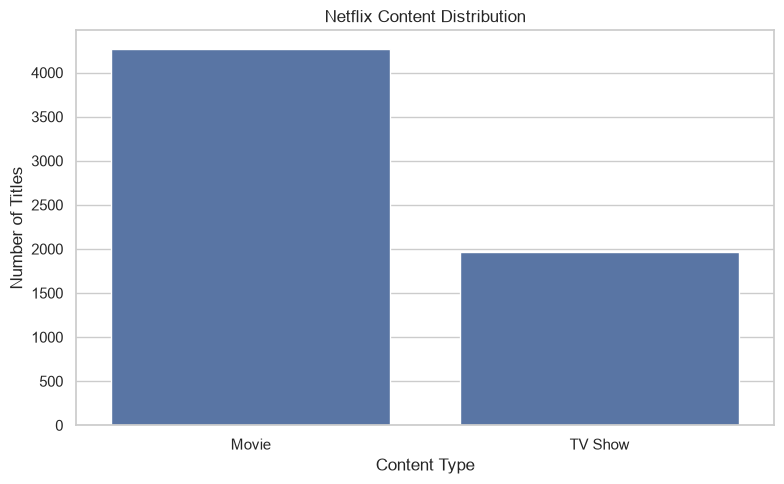

In [4]:
# Chart 1: Movies vs. TV Shows
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="type",
    order=df["type"].value_counts().index
)

plt.title("Netflix Content Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()

plt.savefig(CHART_DIR / "01_content_type.png", dpi=300)
plt.show()

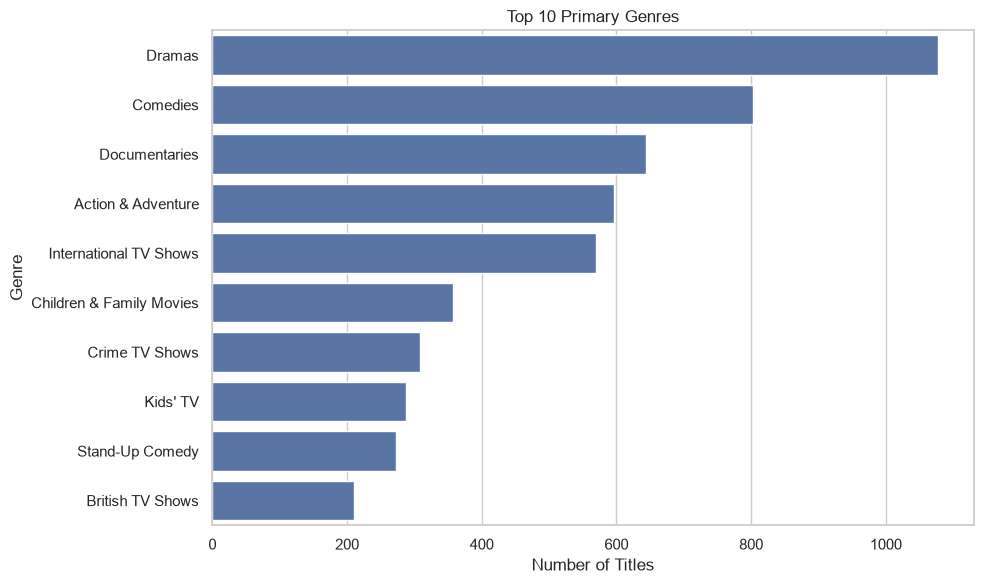

In [5]:
# Chart 2: Top 10 genres
top_genres = df["primary_genre"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index)

plt.title("Top 10 Primary Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(CHART_DIR / "02_top_genres.png", dpi=300)
plt.show()

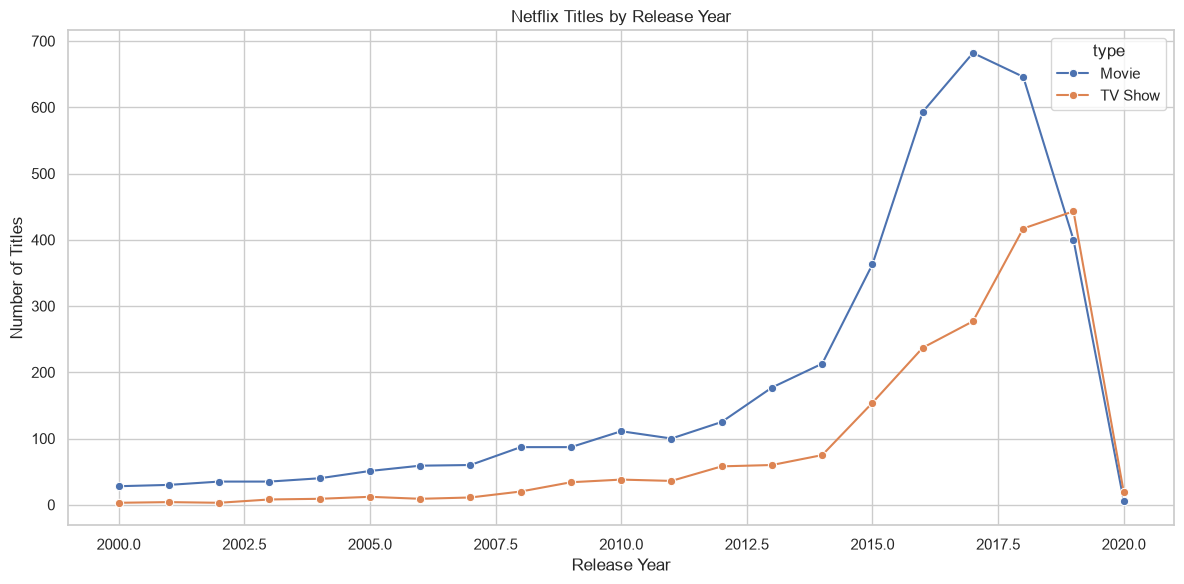

In [6]:
#Chart 3: Content release trends by year
yearly_content = (
    df.dropna(subset=["release_year"])
      .groupby(["release_year", "type"])
      .size()
      .reset_index(name="title_count")
)

yearly_content = yearly_content[
    yearly_content["release_year"] >= 2000
]

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=yearly_content,
    x="release_year",
    y="title_count",
    hue="type",
    marker="o"
)

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()

plt.savefig(CHART_DIR / "03_release_trends.png", dpi=300)
plt.show()

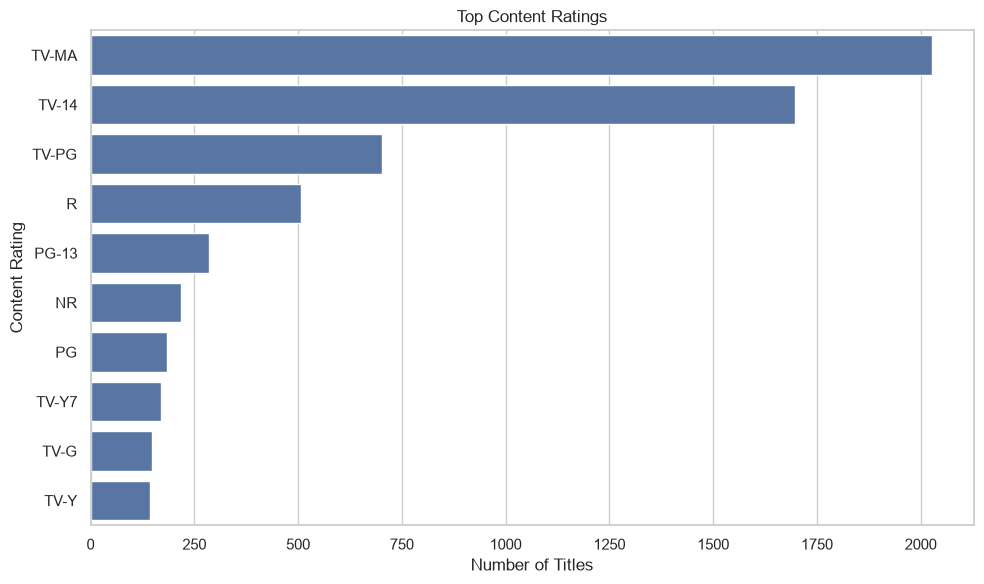

In [7]:
# Chart 4: Content rating distribution
rating_counts = df["rating"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=rating_counts.values, y=rating_counts.index)

plt.title("Top Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.tight_layout()

plt.savefig(CHART_DIR / "04_content_ratings.png", dpi=300)
plt.show()

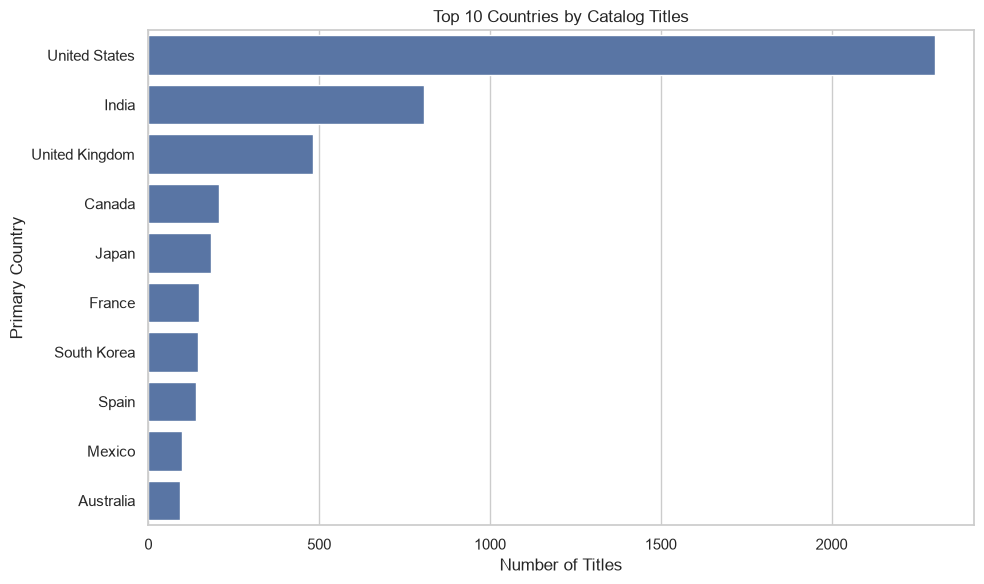

In [12]:
# Chart 5: Top 10 Countries

country_counts = df["primary_country"].value_counts()

# Remove missing and empty country names
country_counts = country_counts[
    country_counts.index.notna()
    & (country_counts.index != "")
].head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index
)

plt.title("Top 10 Countries by Catalog Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Primary Country")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "05_country_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


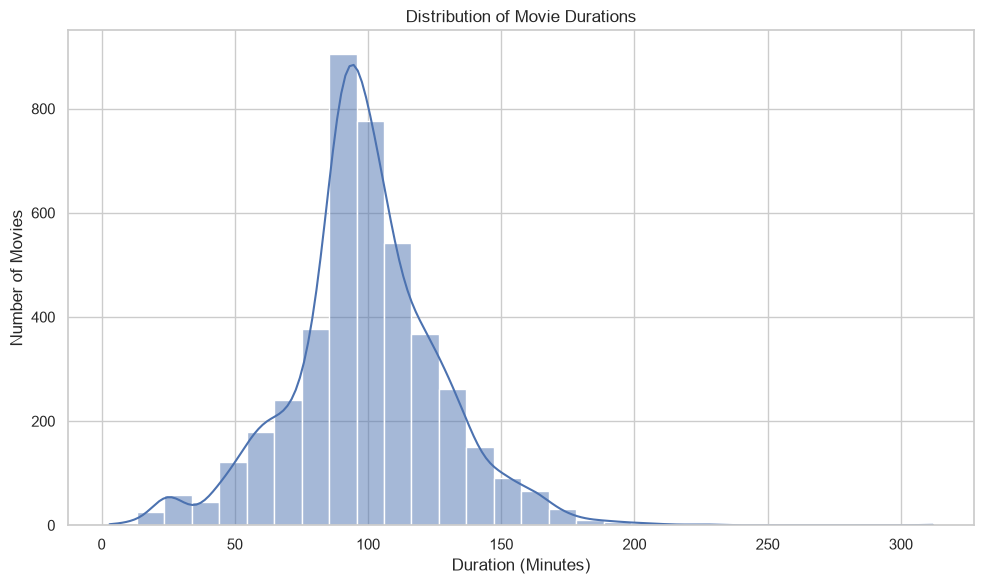

Median movie duration: 98.0
Average movie duration: 99.10082063305978


In [9]:
# Chart 6: Movie duration distribution
movie_data = df.loc[
    df["type"].eq("Movie")
    & df["movie_minutes"].notna()
].copy()

plt.figure(figsize=(10, 6))
sns.histplot(
    data=movie_data,
    x="movie_minutes",
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()

plt.savefig(CHART_DIR / "06_movie_duration.png", dpi=300)
plt.show()

print("Median movie duration:", movie_data["movie_minutes"].median())
print("Average movie duration:", movie_data["movie_minutes"].mean())

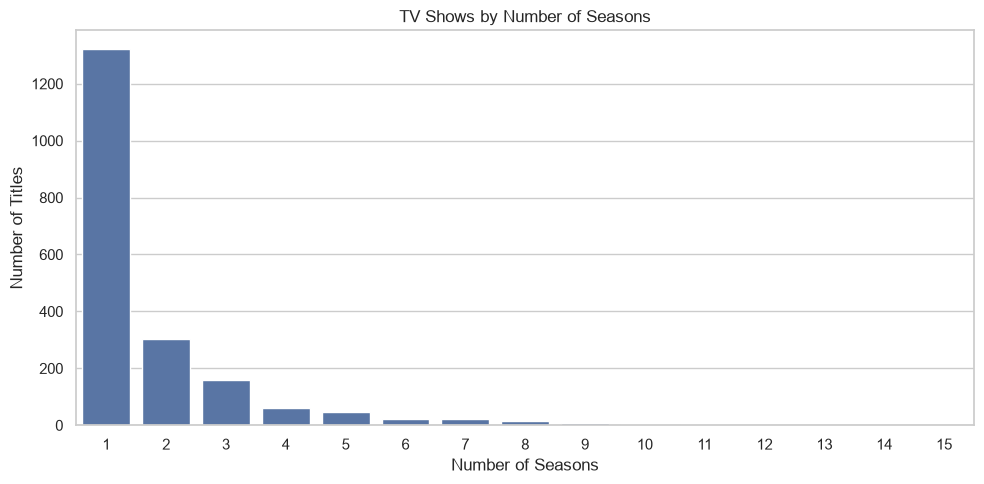

In [10]:
#Chart 7: TV show seasons
tv_data = df.loc[
    df["type"].eq("TV Show")
    & df["seasons"].notna()
]

season_counts = tv_data["seasons"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=season_counts.index.astype(int).astype(str),
    y=season_counts.values
)

plt.title("TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of Titles")
plt.tight_layout()

plt.savefig(CHART_DIR / "07_tv_seasons.png", dpi=300)
plt.show()

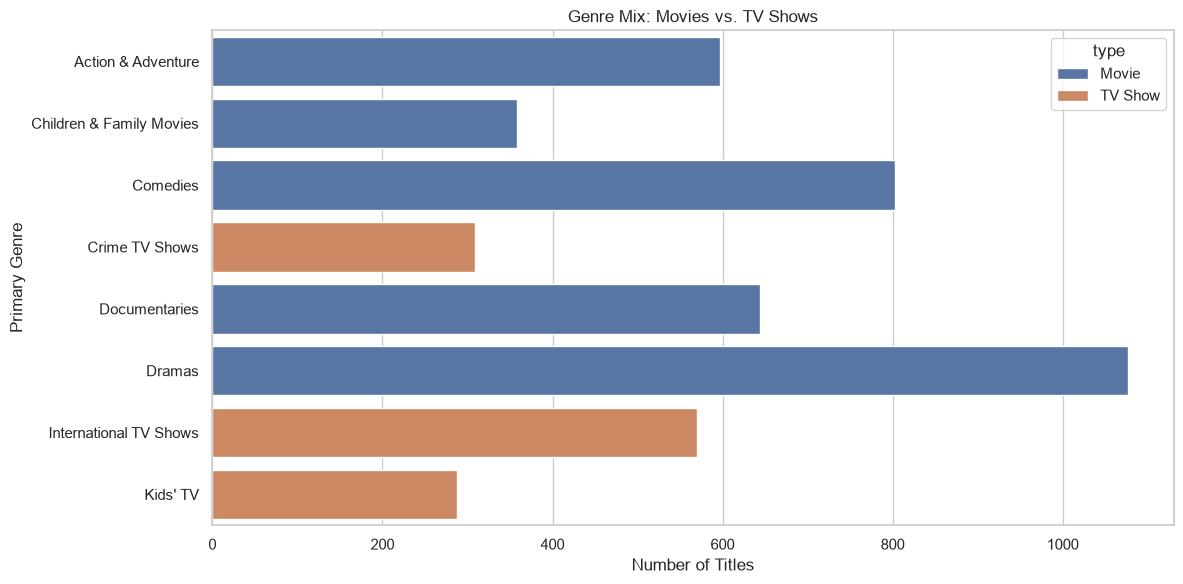

In [11]:
# Chart 8: Genre mix by content type
genre_type = (
    df.dropna(subset=["primary_genre"])
      .groupby(["primary_genre", "type"])
      .size()
      .reset_index(name="title_count")
)

top_8 = (
    genre_type.groupby("primary_genre")["title_count"]
    .sum()
    .nlargest(8)
    .index
)

plot_data = genre_type[
    genre_type["primary_genre"].isin(top_8)
]

plt.figure(figsize=(12, 6))
sns.barplot(
    data=plot_data,
    x="title_count",
    y="primary_genre",
    hue="type"
)

plt.title("Genre Mix: Movies vs. TV Shows")
plt.xlabel("Number of Titles")
plt.ylabel("Primary Genre")
plt.tight_layout()

plt.savefig(CHART_DIR / "08_genre_by_type.png", dpi=300)
plt.show()

In [13]:
content_type_summary = (
    df.groupby("type")
      .size()
      .reset_index(name="total_titles")
)

genre_summary = (
    df.dropna(subset=["primary_genre"])
      .groupby("primary_genre")
      .size()
      .reset_index(name="total_titles")
      .sort_values("total_titles", ascending=False)
)

country_summary = (
    df.dropna(subset=["primary_country"])
      .groupby("primary_country")
      .size()
      .reset_index(name="total_titles")
      .sort_values("total_titles", ascending=False)
)

rating_summary = (
    df.dropna(subset=["rating"])
      .groupby("rating")
      .size()
      .reset_index(name="total_titles")
      .sort_values("total_titles", ascending=False)
)

year_summary = (
    df.dropna(subset=["release_year"])
      .groupby(["release_year", "type"])
      .size()
      .reset_index(name="total_titles")
      .sort_values(["release_year", "type"])
)

duration_summary = movie_data[
    ["title", "release_year", "movie_minutes"]
].copy()

excel_path = EXCEL_DIR / "OTT_Content_Strategy_Summary.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    content_type_summary.to_excel(
        writer, sheet_name="Content Type", index=False
    )
    genre_summary.to_excel(
        writer, sheet_name="Genres", index=False
    )
    country_summary.to_excel(
        writer, sheet_name="Countries", index=False
    )
    rating_summary.to_excel(
        writer, sheet_name="Ratings", index=False
    )
    year_summary.to_excel(
        writer, sheet_name="Release Trends", index=False
    )
    duration_summary.to_excel(
        writer, sheet_name="Movie Duration", index=False
    )

print("Excel workbook saved:", excel_path)

Excel workbook saved: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\OTT_Streaming_Content_Trend_Analysis_Day31\Day4_OTT_Content_Strategy\Excel\OTT_Content_Strategy_Summary.xlsx


In [14]:
print("=" * 50)
print("OTT CONTENT STRATEGY — DAY 4 SUMMARY")
print("=" * 50)

print("\nTotal Titles:", len(df))

print("\nContent Type:")
print(df["type"].value_counts().to_string())

print("\nTop 5 Primary Genres:")
print(df["primary_genre"].value_counts().head(5).to_string())

print("\nTop 5 Primary Countries:")
print(df["primary_country"].value_counts().head(5).to_string())

print("\nTop 5 Content Ratings:")
print(df["rating"].value_counts().head(5).to_string())

print("\nMedian Movie Duration:",
      movie_data["movie_minutes"].median(), "minutes")

print("\nMedian TV Show Seasons:",
      tv_data["seasons"].median())

print("\nCharts saved in:", CHART_DIR)
print("Excel summary:", EXCEL_DIR)

OTT CONTENT STRATEGY — DAY 4 SUMMARY

Total Titles: 6234

Content Type:
type
Movie      4265
TV Show    1969

Top 5 Primary Genres:
primary_genre
Dramas                    1077
Comedies                   803
Documentaries              644
Action & Adventure         597
International TV Shows     570

Top 5 Primary Countries:
primary_country
United States     2302
India              808
United Kingdom     483
Canada             206
Japan              184

Top 5 Content Ratings:
rating
TV-MA    2027
TV-14    1698
TV-PG     701
R         508
PG-13     286

Median Movie Duration: 98.0 minutes

Median TV Show Seasons: 1.0

Charts saved in: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\OTT_Streaming_Content_Trend_Analysis_Day31\Day4_OTT_Content_Strategy\Charts
Excel summary: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\OTT_Streaming_Content_Trend_Analysis_Day31\Day4_OTT_Content_Strategy\Excel
